<a href="https://colab.research.google.com/github/honguyen-lgtm/Portfolio/blob/main/Groceries_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install easyocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 35.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 44.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


In [2]:

import easyocr

reader = easyocr.Reader(['en'], gpu=False)

result = reader.readtext(
    '/content/Walmart_receipt.png',
    detail=0
)

for line in result:
    print(line)


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


WALMART
UTICA
NY
PRACTICE
DATA
DATE:
11/12/2026
WHOLE
MILK
GAL
3.48
EGGS
LARGE
12
CT
2.49
WHITE
BREAD
20
0z
1.98
BANANAS
LB
1.24
RICE
LB
2.28
CHICKEN
BREAST
LB
4.29
SUBTOTAL
15.76
TOTAL
15.76
SAMPLE
ONLY
NOT
REAL
PRICES


In [3]:

import pandas as pd

df = pd.DataFrame(result, columns=["Extracted Text"])

display(df)


,Extracted Text
0,WALMART
1,UTICA
2,NY
3,PRACTICE
4,DATA
5,DATE:
6,11/12/2026
7,WHOLE
8,MILK
9,GAL


In [4]:

import re
import pandas as pd

items = []
product_words = []

for line in result:
    line = line.strip()

    # Check if the line is a price
    if re.fullmatch(r"\d+\.\d{2}", line):
        if product_words:
            items.append({
                "Product": " ".join(product_words),
                "Price": float(line)
            })
            product_words = []

    # Skip receipt header and totals
    elif line.upper() in [
        "WALMART", "UTICA", "NY",
        "PRACTICE", "DATA", "DATE:",
        "SUBTOTAL", "TOTAL"
    ]:
        product_words = []

    # Skip the date
    elif re.fullmatch(r"\d{2}/\d{2}/\d{4}", line):
        continue

    else:
        product_words.append(line)

grocery_df = pd.DataFrame(items)

display(grocery_df)


,Product,Price
0,WHOLE MILK GAL,3.48
1,EGGS LARGE 12 CT,2.49
2,WHITE BREAD 20 0z,1.98
3,BANANAS LB,1.24
4,RICE LB,2.28
5,CHICKEN BREAST LB,4.29


In [5]:

grocery_df["Store"] = "Walmart"
grocery_df["Date"] = "2026-11-12"

display(grocery_df)


,Product,Price,Store,Date
0,WHOLE MILK GAL,3.48,Walmart,2026-11-12
1,EGGS LARGE 12 CT,2.49,Walmart,2026-11-12
2,WHITE BREAD 20 0z,1.98,Walmart,2026-11-12
3,BANANAS LB,1.24,Walmart,2026-11-12
4,RICE LB,2.28,Walmart,2026-11-12
5,CHICKEN BREAST LB,4.29,Walmart,2026-11-12


In [6]:

from pathlib import Path
import easyocr
import pandas as pd
import re

reader = easyocr.Reader(["en"], gpu=False)

all_items = []

# Find all receipt images
receipts = list(Path("/content").glob("*_receipt.png"))

for receipt in receipts:
    print("Processing:", receipt.name)

    # Extract text from receipt
    lines = reader.readtext(str(receipt), detail=0)

    # Identify store from filename
    store = receipt.stem.replace("_receipt", "")
    store = store.replace("_", " ")

    product_words = []
    in_items = False

    for line in lines:
        line = line.strip()

        if line.upper() == "DATE:":
            in_items = True
            continue

        if not in_items:
            continue

        if line.upper() in ["SUBTOTAL", "TOTAL"]:
            break

        if re.fullmatch(r"\d{2}/\d{2}/\d{4}", line):
            continue

        if re.fullmatch(r"\d+\.\d{2}", line):
            if product_words:
                all_items.append({
                    "Store": store,
                    "Product": " ".join(product_words),
                    "Price": float(line),
                    "Receipt": receipt.name
                })
                product_words = []
        else:
            product_words.append(line)

# Create combined table
all_df = pd.DataFrame(all_items)

display(all_df)
print("Total grocery items:", len(all_df))


Processing: Price_Chopper_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Processing: Aldi_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Processing: Hannaford_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (2 outputs left out)

Processing: Walmart_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,Store,Product,Price,Receipt
0,Price Chopper,WHOLE MILK GAL,3.79,Price_Chopper_receipt.png
1,Price Chopper,EGGS LARGE 12 CT,2.69,Price_Chopper_receipt.png
2,Price Chopper,WHITE BREAD 20 0z,2.39,Price_Chopper_receipt.png
3,Price Chopper,BANANAS LB,1.34,Price_Chopper_receipt.png
4,Price Chopper,RICE LB,2.59,Price_Chopper_receipt.png
5,Price Chopper,CHICKEN BREAST LB,4.49,Price_Chopper_receipt.png
6,Aldi,WHOLE MILK GAL,3.19,Aldi_receipt.png
7,Aldi,EGGS LARGE 12 CT,2.29,Aldi_receipt.png
8,Aldi,WHITE BREAD 20 0z,1.65,Aldi_receipt.png
9,Aldi,BANANAS LB,1.10,Aldi_receipt.png


Total grocery items: 28


In [7]:

# Count extracted items by store
print(all_df.groupby("Store").size())

# Check total extracted items
print("Total items:", len(all_df))


Store
Aldi             5
Chanatrys        5
Hannaford        6
Price Chopper    6
Walmart          6
dtype: int64
Total items: 28


In [8]:

# Find the incorrectly combined row
mask = (
    (all_df["Store"] == "Chanatrys") &
    (all_df["Product"].str.contains(
        "WHOLE MILK GAL 3.69 EGGS", na=False
    ))
)

# Remove the incorrect row
all_df = all_df.loc[~mask].copy()

# Add the two corrected products
corrected = pd.DataFrame([
    {
        "Store": "Chanatrys",
        "Product": "WHOLE MILK GAL",
        "Price": 3.69,
        "Receipt": "Chanatrys_receipt.png"
    },
    {
        "Store": "Chanatrys",
        "Product": "EGGS LARGE 12 CT",
        "Price": 2.79,
        "Receipt": "Chanatrys_receipt.png"
    }
])

all_df = pd.concat(
    [all_df, corrected],
    ignore_index=True
)

display(all_df)


,Store,Product,Price,Receipt
0,Price Chopper,WHOLE MILK GAL,3.79,Price_Chopper_receipt.png
1,Price Chopper,EGGS LARGE 12 CT,2.69,Price_Chopper_receipt.png
2,Price Chopper,WHITE BREAD 20 0z,2.39,Price_Chopper_receipt.png
3,Price Chopper,BANANAS LB,1.34,Price_Chopper_receipt.png
4,Price Chopper,RICE LB,2.59,Price_Chopper_receipt.png
5,Price Chopper,CHICKEN BREAST LB,4.49,Price_Chopper_receipt.png
6,Aldi,WHOLE MILK GAL,3.19,Aldi_receipt.png
7,Aldi,EGGS LARGE 12 CT,2.29,Aldi_receipt.png
8,Aldi,WHITE BREAD 20 0z,1.65,Aldi_receipt.png
9,Aldi,BANANAS LB,1.10,Aldi_receipt.png


In [9]:

# Count products from each store
print(all_df.groupby("Store").size())

# Check total products
print("Total grocery items:", len(all_df))


Store
Aldi             5
Chanatrys        7
Hannaford        6
Price Chopper    6
Walmart          6
dtype: int64
Total grocery items: 30


In [10]:

# Display Aldi grocery items
display(all_df[all_df["Store"] == "Aldi"])

# Display Chanatry's grocery items
display(all_df[all_df["Store"] == "Chanatrys"])


,Store,Product,Price,Receipt
6,Aldi,WHOLE MILK GAL,3.19,Aldi_receipt.png
7,Aldi,EGGS LARGE 12 CT,2.29,Aldi_receipt.png
8,Aldi,WHITE BREAD 20 0z,1.65,Aldi_receipt.png
9,Aldi,BANANAS LB,1.10,Aldi_receipt.png
10,Aldi,RICE LB,2.09,Aldi_receipt.png


,Store,Product,Price,Receipt
17,Chanatrys,WHOLE MILK GAL 3. 69 EGGS LARGE 12 CT,2.79,Chanatrys_receipt.png
18,Chanatrys,WHITE BREAD 20 0z,2.49,Chanatrys_receipt.png
19,Chanatrys,BANANAS LB,1.38,Chanatrys_receipt.png
20,Chanatrys,RICE LB,2.69,Chanatrys_receipt.png
21,Chanatrys,CHICKEN BREAST LB,4.59,Chanatrys_receipt.png
28,Chanatrys,WHOLE MILK GAL,3.69,Chanatrys_receipt.png
29,Chanatrys,EGGS LARGE 12 CT,2.79,Chanatrys_receipt.png


In [11]:

# Remove the incorrectly combined Chanatry's row
all_df = all_df[
    ~(
        (all_df["Store"] == "Chanatrys") &
        (all_df["Product"].str.contains(
            "EGGS", na=False
        )) &
        (all_df["Product"].str.contains(
            "MILK", na=False
        ))
    )
].copy()

# Add Aldi's missing chicken
aldi_chicken = pd.DataFrame([{
    "Store": "Aldi",
    "Product": "CHICKEN BREAST LB",
    "Price": 3.99,
    "Receipt": "Aldi_receipt.png"
}])

all_df = pd.concat(
    [all_df, aldi_chicken],
    ignore_index=True
)

# Check the results
print(all_df.groupby("Store").size())
print("Total items:", len(all_df))


Store
Aldi             6
Chanatrys        6
Hannaford        6
Price Chopper    6
Walmart          6
dtype: int64
Total items: 30


In [15]:

from pathlib import Path

# Locate your Grocery Project folder
output_folder = Path(
    "/content/drive/MyDrive/Grocery_Project/Output"
)

# Create Output folder if needed
output_folder.mkdir(parents=True, exist_ok=True)

# Save your grocery data
output_file = output_folder / "grocery_prices.xlsx"

all_df.to_excel(output_file, index=False)

print("Excel file saved successfully!")
print(output_file)


Excel file saved successfully!
/content/drive/MyDrive/Grocery_Project/Output/grocery_prices.xlsx


In [16]:

# Compare grocery prices by store
comparison = all_df.pivot_table(
    index="Product",
    columns="Store",
    values="Price",
    aggfunc="mean"
)

display(comparison.round(2))


Store,Aldi,Chanatrys,Hannaford,Price Chopper,Walmart
Product,,,,,
BANANAS LB,1.10,1.38,1.30,1.34,1.24
CHICKEN BREAST LB,3.99,4.59,4.39,4.49,4.29
EGGS LARGE 12 CT,2.29,2.79,2.59,2.69,2.49
RICE LB,2.09,2.69,2.49,2.59,2.28
WHITE BREAD 20 0z,1.65,2.49,2.29,2.39,1.98
WHOLE MILK GAL,3.19,3.69,3.59,3.79,3.48


In [17]:

# Calculate total grocery cost at each store
basket_total = (
    comparison.sum(axis=0)
    .sort_values()
)

print("Grocery basket cost by store:")
print(basket_total)


Grocery basket cost by store:
Store
Aldi             14.31
Walmart          15.76
Hannaford        16.65
Price Chopper    17.29
Chanatrys        17.63
dtype: float64


In [18]:

# Save grocery price comparison
comparison.to_excel(
    output_folder / "store_comparison.xlsx"
)

# Save grocery store ranking
basket_total.to_frame(
    name="Basket Total"
).to_excel(
    output_folder / "store_ranking.xlsx"
)

print("Comparison and ranking saved!")


Comparison and ranking saved!


In [21]:

from pathlib import Path
import pandas as pd
import easyocr
import re
import hashlib

base = Path("/content/drive/MyDrive/Grocery_Project")

input_folder = base / "Input"
output_folder = base / "Output"

input_folder.mkdir(parents=True, exist_ok=True)
output_folder.mkdir(parents=True, exist_ok=True)

master_file = output_folder / "grocery_prices.xlsx"

reader = easyocr.Reader(["en"], gpu=False)

# Read your existing grocery data
if master_file.exists():
    master = pd.read_excel(master_file)
else:
    master = pd.DataFrame(
        columns=["Store", "Product", "Price", "Receipt"]
    )

# Track processed receipts using image fingerprints
log_file = output_folder / "processed_receipts.csv"

if log_file.exists():
    processed = pd.read_csv(log_file)
else:
    processed = pd.DataFrame(columns=["Receipt_ID", "Receipt"])

known_ids = set(processed["Receipt_ID"].astype(str))

for receipt in input_folder.glob("*.png"):

    receipt_id = hashlib.sha256(
        receipt.read_bytes()
    ).hexdigest()

    if receipt_id in known_ids:
        print("Already processed:", receipt.name)
        continue

    print("Reading:", receipt.name)

    lines = reader.readtext(str(receipt), detail=0)

    store = receipt.stem.replace("_receipt", "")
    store = store.replace("_", " ")

    product_words = []
    new_items = []
    in_items = False

    for line in lines:
        line = line.strip()

        if line.upper() == "DATE:":
            in_items = True
            continue

        if not in_items:
            continue

        if line.upper() in ["SUBTOTAL", "TOTAL"]:
            break

        if re.fullmatch(r"\d{2}/\d{2}/\d{4}", line):
            continue

        if re.fullmatch(r"\d+\.\d{2}", line):
            if product_words:
                new_items.append({
                    "Store": store,
                    "Product": " ".join(product_words),
                    "Price": float(line),
                    "Receipt": receipt.name
                })
                product_words = []
        else:
            product_words.append(line)

    if not new_items:
        print("Needs review:", receipt.name)
        continue

    # Review OCR results before saving
    print(pd.DataFrame(new_items).to_string(index=False))
    answer = input(
        "Are all items correct? (yes/no): "
    ).strip().lower()

    if answer != "yes":
        print("Not imported. Review this receipt.")
        continue

    # Append new items to existing data
    master = pd.concat(
        [master, pd.DataFrame(new_items)],
        ignore_index=True
    )

    # Save updated master file
    master.to_excel(master_file, index=False)

    # Record processed receipt
    processed.loc[len(processed)] = [
        receipt_id, receipt.name
    ]
    processed.to_csv(log_file, index=False)
    known_ids.add(receipt_id)

    print("Saved:", receipt.name)

print("Automation finished!")


Automation finished!


In [24]:

from pathlib import Path

input_folder = Path(
    "/content/drive/MyDrive/Grocery_Project/Input"
)

print("Folder exists:", input_folder.exists())

for file in input_folder.iterdir():
    print(file.name)


Folder exists: True
Price_Chopper_receipt.png
.ipynb_checkpoints
Aldi_receipt.png
Hannaford_receipt.png
Walmart _receipt2.png
Chanatrys_receipt.png
Walmart_receipt.png


In [25]:

import easyocr
from pathlib import Path

input_folder = Path(
    "/content/drive/MyDrive/Grocery_Project/Input"
)

reader = easyocr.Reader(["en"], gpu=False)

# Find receipt images
receipts = list(input_folder.glob("*.png"))

print("Receipts found:", len(receipts))

for receipt in receipts:
    print("\nReading:", receipt.name)

    lines = reader.readtext(
        str(receipt),
        detail=0
    )

    for line in lines:
        print(line)


Receipts found: 6

Reading: Price_Chopper_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


PRICE
CHOPPER
UTICA
NY
PRACTICE
DATA
DATE:
11/12/2026
WHOLE
MILK
GAL
3.79
EGGS
LARGE
12
CT
2.69
WHITE
BREAD
20
0z
2.39
BANANAS
LB
1.34
RICE
LB
2.59
CHICKEN
BREAST
LB
4.49
SUBTOTAL
17.29
TOTAL
17.29
SAMPLE
ONLY
NOT
REAL
PRICES

Reading: Aldi_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


ALDI
UTICA
NY
PRACTICE
DATA
DATE:
11/12/2026
WHOLE
MILK
GAL
3.19
EGGS
LARGE
12
CT
2.29
WHITE
BREAD
20
0z
1.65
BANANAS
LB
1.10
RICE
LB
2.09
CHICKEN
BREAST
LB
3. 99
SUBTOTAL
14.31
TOTAL
14.31
SAMPLE
ONLY
NOT
REAL
PRICES

Reading: Hannaford_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


CHANATRYS
UTICA
NY
PRACTICE
DATA
DATE:
11/12/2026
WHOLE
MILK
GAL
3. 69
EGGS
LARGE
12
CT
2.79
WHITE
BREAD
20
0z
2.49
BANANAS
LB
1.38
RICE
LB
2.69
CHICKEN
BREAST
LB
4.59
SUBTOTAL
17.63
TOTAL
17.63
SAMPLE
ONLY
NOT
REAL
PRICES

Reading: Walmart_receipt.png


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


WALMART
UTICA
NY
PRACTICE
DATA
DATE:
11/12/2026
WHOLE
MILK
GAL
3.48
EGGS
LARGE
12
CT
2.49
WHITE
BREAD
20
0z
1.98
BANANAS
LB
1.24
RICE
LB
2.28
CHICKEN
BREAST
LB
4.29
SUBTOTAL
15.76
TOTAL
15.76
SAMPLE
ONLY
NOT
REAL
PRICES


In [26]:

from pathlib import Path

input_folder = Path(
    "/content/drive/MyDrive/Grocery_Project/Input"
)

for receipt in input_folder.glob("*.png"):
    print(receipt.name)


Price_Chopper_receipt.png
Aldi_receipt.png
Hannaford_receipt.png
Walmart _receipt2.png
Chanatrys_receipt.png
Walmart_receipt.png


In [30]:

from pathlib import Path

input_folder = Path(
    "/content/drive/MyDrive/Grocery_Project/Input"
)

# Find any file containing "walmart" and "receipt2"
matches = [
    file for file in input_folder.iterdir()
    if file.is_file()
    and "walmart" in file.name.lower()
    and "receipt2" in file.name.lower()
]

print("Matching files:", matches)


Matching files: [PosixPath('/content/drive/MyDrive/Grocery_Project/Input/Walmart _receipt2.png')]


In [31]:

if matches:
    receipt = matches[0]

    new_lines = reader.readtext(
        str(receipt),
        detail=0
    )

    for line in new_lines:
        print(line)
else:
    print("Receipt not found. Check Google Drive.")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Walmart
Neighborhood Market
4512
Commercial
Dr
Utica,
NY
13502
(315)
735-2045
REG#
003
TRN#2894
11/12/2026
10:24 AM
WHOLE
MILK
GAL
3.48
EGGS
LARGE
12
CT
2.49
WHITE
BREAD
20
0z
1.98
BANANAS
LB
1.24
RICE
LB
2.28
CHICKEN
BREAST
LB
4.29
SUBTOTAL
15.76
TAX
8 . 00%
0 . 00
TOTAL
S15.76
VISA
****1234
15.76
APPROVED
189732
Thank
you
for shopping
at Walmart!
Save
more
with
the
Walmart
app _
0068432894011226


In [32]:

import re
import pandas as pd

items = []
product_words = []
started = False

for line in new_lines:
    line = line.strip()

    # Start after the receipt time
    if "AM" in line or "PM" in line:
        started = True
        continue

    if not started:
        continue

    # Stop at subtotal
    if line.upper() == "SUBTOTAL":
        break

    # Identify prices
    if re.fullmatch(r"\d+\.\d{2}", line):
        if product_words:
            items.append({
                "Store": "Walmart",
                "Product": " ".join(product_words),
                "Price": float(line),
                "Receipt": receipt.name
            })
            product_words = []
    else:
        product_words.append(line)

new_df = pd.DataFrame(items)

display(new_df)
print("Items extracted:", len(new_df))


,Store,Product,Price,Receipt
0,Walmart,WHOLE MILK GAL,3.48,Walmart _receipt2.png
1,Walmart,EGGS LARGE 12 CT,2.49,Walmart _receipt2.png
2,Walmart,WHITE BREAD 20 0z,1.98,Walmart _receipt2.png
3,Walmart,BANANAS LB,1.24,Walmart _receipt2.png
4,Walmart,RICE LB,2.28,Walmart _receipt2.png
5,Walmart,CHICKEN BREAST LB,4.29,Walmart _receipt2.png


Items extracted: 6


In [33]:

import pandas as pd
import hashlib
from pathlib import Path

output_file = Path(
    "/content/drive/MyDrive/Grocery_Project/Output/grocery_prices.xlsx"
)

# Open your existing Excel file
master_df = pd.read_excel(output_file)

# Create a unique ID for the receipt
receipt_id = hashlib.sha256(
    receipt.read_bytes()
).hexdigest()

# Create receipt IDs for existing records
if "Receipt_ID" not in master_df.columns:
    master_df["Receipt_ID"] = ""

# Avoid importing the same receipt again
if receipt_id in master_df["Receipt_ID"].astype(str).values:
    print("Receipt already imported. Skipping.")

else:
    # Add the new receipt ID
    new_df["Receipt_ID"] = receipt_id

    # Combine old and new data
    updated_df = pd.concat(
        [master_df, new_df],
        ignore_index=True
    )

    # Save the updated Excel file
    updated_df.to_excel(output_file, index=False)

    print("New receipt added successfully!")
    print("Total grocery items:", len(updated_df))


New receipt added successfully!
Total grocery items: 36


In [34]:

# Reload the updated Excel file
master_df = pd.read_excel(output_file)

# Count total grocery items
print("Total grocery items:", len(master_df))

# Count items by store
print(master_df.groupby("Store").size())


Total grocery items: 36
Store
Aldi              6
Chanatrys         6
Hannaford         6
Price Chopper     6
Walmart          12
dtype: int64


In [35]:

from pathlib import Path
import pandas as pd
import easyocr
import hashlib
import re

# 1. Google Drive folders
base = Path("/content/drive/MyDrive/Grocery_Project")
input_folder = base / "Input"
output_folder = base / "Output"

output_folder.mkdir(parents=True, exist_ok=True)
master_file = output_folder / "grocery_prices.xlsx"

# 2. Load existing Excel data
if master_file.exists():
    master = pd.read_excel(master_file)
else:
    master = pd.DataFrame(columns=[
        "Store", "Product", "Price",
        "Receipt", "Receipt_ID"
    ])

if "Receipt_ID" not in master.columns:
    master["Receipt_ID"] = ""

reader = easyocr.Reader(["en"], gpu=False)

# 3. Find receipt images
receipts = [
    p for p in input_folder.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

for receipt in receipts:

    # Create a unique ID from the image
    receipt_id = hashlib.sha256(
        receipt.read_bytes()
    ).hexdigest()

    # Skip already imported receipts
    if receipt_id in master["Receipt_ID"].astype(str).values:
        print("Already imported:", receipt.name)
        continue

    # Protect previously imported practice receipts
    old_receipts = set(master.loc[
        master["Receipt_ID"].isna() |
        (master["Receipt_ID"].astype(str).str.strip() == ""),
        "Receipt"
    ].astype(str))

    if receipt.name in old_receipts:
        print("Previously imported:", receipt.name)
        continue

    print("\nReading:", receipt.name)

    # 4. Extract text using OCR
    lines = reader.readtext(str(receipt), detail=0)
    lines = [str(x).strip() for x in lines]

    # Identify store
    store = receipt.stem.split("_receipt")[0]
    store = store.replace("_", " ")

    # 5. Extract products and prices
    items = []
    product_words = []
    started = False

    for line in lines:
        upper = line.upper()

        # Start after DATE or transaction time
        if upper == "DATE:" or re.search(
            r"\b\d{1,2}:\d{2}\s*(AM|PM)\b", upper
        ):
            started = True
            continue

        if not started:
            continue

        if upper in ["SUBTOTAL", "TOTAL"]:
            break

        # Skip dates and times
        if re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", line):
            continue

        if re.fullmatch(r"\d+\.\d{2}", line):
            if product_words:
                items.append({
                    "Store": store,
                    "Product": " ".join(product_words),
                    "Price": float(line),
                    "Receipt": receipt.name,
                    "Receipt_ID": receipt_id
                })
                product_words = []
        else:
            product_words.append(line)

    if not items:
        print("No items found. Needs review.")
        continue

    # 6. Review before saving
    new_df = pd.DataFrame(items)
    display(new_df[["Store", "Product", "Price"]])

    answer = input(
        "Are ALL products and prices correct? (yes/no): "
    ).strip().lower()

    if answer != "yes":
        print("Skipped. No Excel changes made.")
        continue

    # 7. Append and save
    updated = pd.concat(
        [master, new_df],
        ignore_index=True
    )

    updated.to_excel(master_file, index=False)
    master = updated

    print("Saved:", receipt.name)

# 8. Update store comparison
comparison = master.pivot_table(
    index="Product",
    columns="Store",
    values="Price",
    aggfunc="mean"
)

# Only compare products present at every store
complete = comparison.dropna()

if not complete.empty:
    ranking = complete.sum().sort_values()

    comparison.to_excel(
        output_folder / "store_comparison.xlsx"
    )

    ranking.to_frame("Basket Total").to_excel(
        output_folder / "store_ranking.xlsx"
    )

    print("\nStore ranking:")
    print(ranking)
else:
    print("No complete comparison basket yet.")

print("\nAutomation finished!")
print("Total records:", len(master))


Previously imported: Price_Chopper_receipt.png
Previously imported: Aldi_receipt.png
Previously imported: Hannaford_receipt.png
Already imported: Walmart _receipt2.png
Previously imported: Chanatrys_receipt.png
Previously imported: Walmart_receipt.png

Store ranking:
Store
Aldi             14.31
Walmart          15.76
Hannaford        16.65
Price Chopper    17.29
Chanatrys        17.63
dtype: float64

Automation finished!
Total records: 36


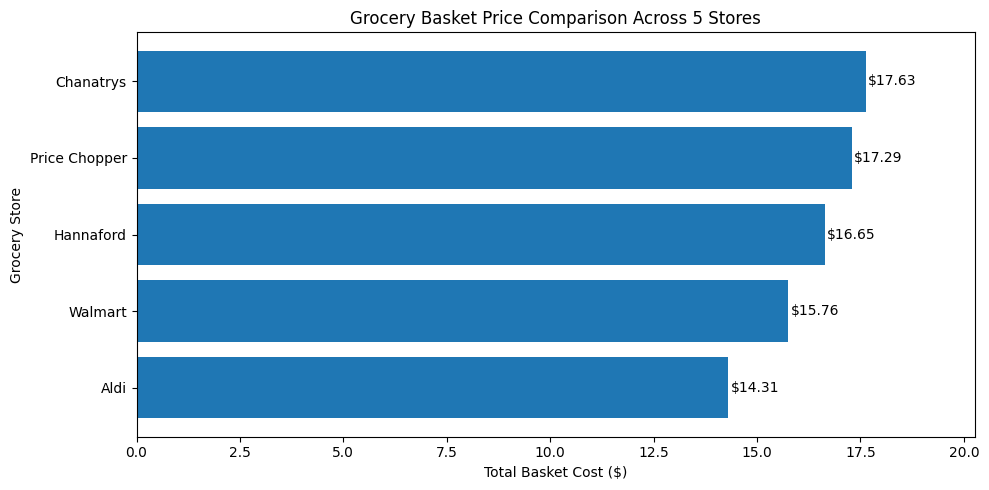

Chart saved successfully!


In [39]:

import pandas as pd
import matplotlib.pyplot as plt

# Load your grocery data
df = pd.read_excel(output_file)

# Calculate average price per product at each store
comparison = df.pivot_table(
    index="Product",
    columns="Store",
    values="Price",
    aggfunc="mean"
)

# Compare the same products across stores
basket = comparison.dropna().sum().sort_values()

# Create bar chart
plt.figure(figsize=(10, 5))
bars = plt.barh(basket.index, basket.values)

plt.xlabel("Total Basket Cost ($)")
plt.ylabel("Grocery Store")
plt.title("Grocery Basket Price Comparison Across 5 Stores")

# Add price labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"${bar.get_width():.2f}",
        va="center"
    )

plt.xlim(0, basket.max() * 1.15)
plt.tight_layout()

# Save the chart BEFORE displaying it
plt.savefig(
    "/content/drive/MyDrive/Grocery_Project/Output/grocery_comparison.png",
    dpi=300,
    bbox_inches="tight",
    format="png"
)

plt.show()

print("Chart saved successfully!")